In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("../data/train")
IMG_DIR = DATA_DIR / "images"
LABEL_DIR = DATA_DIR / "labels"
TARGET_DIR = DATA_DIR / "targets"

print("images :", IMG_DIR.exists())
print("labels :", LABEL_DIR.exists())
print("targets:", TARGET_DIR.exists())

images : True
labels : True
targets: True


In [2]:
# Pre/post eşleşme kontrolü: her afet öncesi görüntünün bir afet sonrası karşılığı var mı?
pre_ids = {p.name.replace("_pre_disaster.png", "") for p in IMG_DIR.glob("*_pre_disaster.png")}
post_ids = {p.name.replace("_post_disaster.png", "") for p in IMG_DIR.glob("*_post_disaster.png")}
post_json_count = len(list(LABEL_DIR.glob("*_post_disaster.json")))

print(f"Pre-disaster : {len(pre_ids)}")
print(f"Post-disaster: {len(post_ids)}")
print(f"Eşleşmiş çift: {len(pre_ids & post_ids)}")
print(f"Pre-only     : {len(pre_ids - post_ids)}")
print(f"Post-only    : {len(post_ids - pre_ids)}")
print(f"Post JSON    : {post_json_count}")

Pre-disaster : 2799
Post-disaster: 2799
Eşleşmiş çift: 2799
Pre-only     : 0
Post-only    : 0
Post JSON    : 2799


In [3]:
rows = []
for path in sorted(LABEL_DIR.glob("*_post_disaster.json")):
    label = json.loads(path.read_text(encoding="utf-8"))
    meta = label["metadata"]
    for b in label["features"]["xy"]:
        rows.append({
            "image_id": path.stem.replace("_post_disaster", ""),
            "disaster": meta["disaster"],
            "disaster_type": meta["disaster_type"],
            "damage": b["properties"].get("subtype", "unknown"),
        })

buildings = pd.DataFrame(rows)
print(f"Toplam bina sayısı: {len(buildings):,}")
buildings.head()

Toplam bina sayısı: 162,787


,image_id,disaster,disaster_type,damage
0,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage
1,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage
2,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage
3,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage
4,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage


In [4]:
order = ["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"]

table = pd.crosstab(
    [buildings["disaster_type"], buildings["disaster"]],
    buildings["damage"],
).reindex(columns=order, fill_value=0)

table["toplam_bina"] = table[order].sum(axis=1)

# Toplam çift: dosyalardan sayılır (binasız görüntüler dahil)
pair_counts = pd.Series(
    [p.name.split("_")[0] for p in LABEL_DIR.glob("*_post_disaster.json")]
).value_counts()
table["toplam_cift"] = table.index.get_level_values("disaster").map(pair_counts).values

# Binalı çift: en az bir bina içeren görüntüler
table["binali_cift"] = buildings.groupby(["disaster_type", "disaster"])["image_id"].nunique()

table["hasarli_oran_%"] = (
    table[["minor-damage", "major-damage", "destroyed"]].sum(axis=1) / table["toplam_bina"] * 100
).round(1)

table

damage                             no-damage  minor-damage  major-damage  \
disaster_type disaster                                                     
earthquake    mexico-earthquake        32066           110            18   
fire          santa-rosa-wildfire       9285            78            63   
              socal-fire                8638            83            51   
flooding      hurricane-florence        4689           132          1245   
              hurricane-harvey         11423          2663          8238   
              midwest-flooding          8128           149           119   
tsunami       palu-tsunami             25455             1           571   
volcano       guatemala-volcano          639             9             9   
wind          hurricane-matthew         2515          6548          1945   
              hurricane-michael        14588          5207          1902   

damage                             destroyed  un-classified  toplam_bina  \
disaster_type disaster                                                     
earthquake    mexico-earthquake            2             75        32271   
fire          santa-rosa-wildfire       3471             53        12950   
              socal-fire                1329            374        10475   
flooding      hurricane-florence          54            326         6446   
              hurricane-harvey           401            289        23014   
              midwest-flooding            75            285         8756   
tsunami       palu-tsunami              4966            401        31394   
volcano       guatemala-volcano           25            174          856   
wind          hurricane-matthew         2147            784        13939   
              hurricane-michael          757            232        22686   

damage                             toplam_cift  binali_cift  hasarli_oran_%  
disaster_type disaster                                                       
earthquake    mexico-earthquake            121          121             0.4  
fire          santa-rosa-wildfire          226          219            27.9  
              socal-fire                   823          408            14.0  
flooding      hurricane-florence           319          306            22.2  
              hurricane-harvey             319          300            49.1  
              midwest-flooding             279          244             3.9  
tsunami       palu-tsunami                 113          111            17.6  
volcano       guatemala-volcano             18           17             5.0  
wind          hurricane-matthew            238          223            76.3  
              hurricane-michael            343          334            34.7

damage
no-damage        72.1 %
minor-damage      9.2 %
major-damage      8.7 %
destroyed         8.1 %
un-classified     1.8 %
Name: count, dtype: str


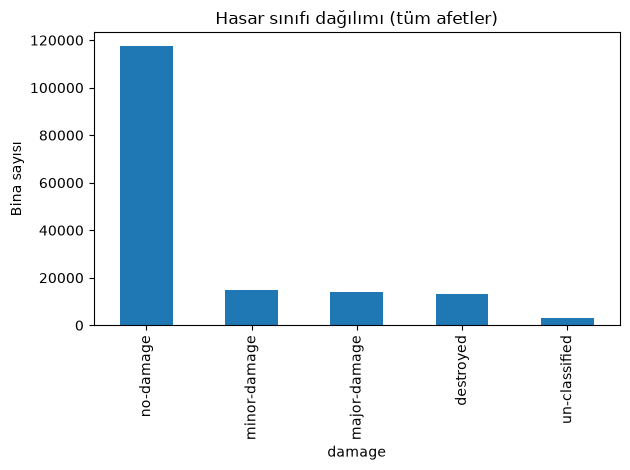

In [5]:
overall = buildings["damage"].value_counts().reindex(order, fill_value=0)
print((overall / overall.sum() * 100).round(1).astype(str) + " %")

overall.plot(kind="bar", title="Hasar sınıfı dağılımı (tüm afetler)")
plt.ylabel("Bina sayısı")
plt.tight_layout()
plt.show()

In [6]:
print(table.to_string())

damage                             no-damage  minor-damage  major-damage  destroyed  un-classified  toplam_bina  toplam_cift  binali_cift  hasarli_oran_%
disaster_type disaster                                                                                                                                   
earthquake    mexico-earthquake        32066           110            18          2             75        32271          121          121             0.4
fire          santa-rosa-wildfire       9285            78            63       3471             53        12950          226          219            27.9
              socal-fire                8638            83            51       1329            374        10475          823          408            14.0
flooding      hurricane-florence        4689           132          1245         54            326         6446          319          306            22.2
              hurricane-harvey         11423          2663          8238    

In [7]:
Path("../results").mkdir(exist_ok=True)
table.to_csv("../results/faz2_afet_hasar_dagilimi.csv", encoding="utf-8-sig")
print("Kaydedildi")

Kaydedildi


## Hurricane Matthew

Hurricane Matthew: 238 toplam görüntü çifti; bunların 223'ünde en az bir bina anotasyonu bulunmaktadır.

- **238** = Matthew'e ait toplam pre/post görüntü çifti (ham dosya sayımı)
- **223** = içinde en az bir bina anotasyonu bulunan görüntü çifti
- Aradaki 15 çift bina anotasyonu içermiyor. Bu iki sayı birbirinin alternatifi değil, farklı tanımlardır.

In [8]:
matthew = buildings[buildings["disaster"] == "hurricane-matthew"]
matthew_pairs = len(list(LABEL_DIR.glob("hurricane-matthew_*_post_disaster.json")))

print(f"Toplam görüntü çifti          : {matthew_pairs}")
print(f"En az bir bina içeren çift    : {matthew['image_id'].nunique()}")
print(f"Toplam bina                   : {len(matthew):,}\n")
print(matthew["damage"].value_counts())

Toplam görüntü çifti          : 238
En az bir bina içeren çift    : 223
Toplam bina                   : 13,939

damage
minor-damage     6548
no-damage        2515
destroyed        2147
major-damage     1945
un-classified     784
Name: count, dtype: int64


no-damage     : 2,515 bina
minor-damage  : 6,548 bina
major-damage  : 1,945 bina
destroyed     : 2,147 bina


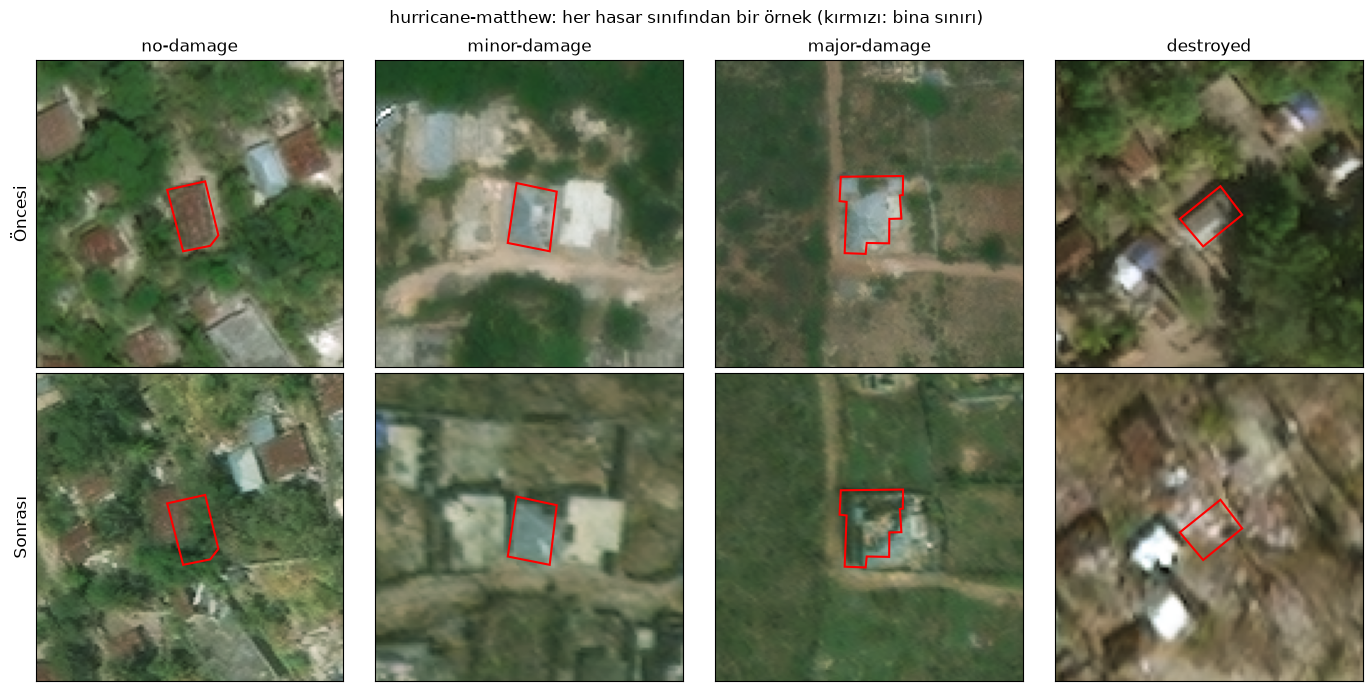

In [9]:
import re
import random
import matplotlib.patches as patches

EVENT = "hurricane-matthew"
CLASSES = ["no-damage", "minor-damage", "major-damage", "destroyed"]

from shapely import wkt as shapely_wkt

def wkt_to_xy(wkt_text):
    """WKT poligonunu shapely ile okuyup dış sınır koordinatlarını [(x, y), ...] olarak döndürür."""
    if not wkt_text:
        return []
    geom = shapely_wkt.loads(wkt_text)
    if geom.geom_type == "MultiPolygon":
        geom = max(geom.geoms, key=lambda g: g.area)
    return list(geom.exterior.coords)

# 1) Matthew'deki binaları sınıflarına göre topla
examples = {c: [] for c in CLASSES}
for path in sorted(LABEL_DIR.glob(f"{EVENT}_*_post_disaster.json")):
    label = json.loads(path.read_text(encoding="utf-8"))
    for b in label["features"]["xy"]:
        damage = b["properties"].get("subtype")
        if damage in examples:
            xy = wkt_to_xy(b["wkt"])
            xs, ys = zip(*xy)
            area = (max(xs) - min(xs)) * (max(ys) - min(ys))
            examples[damage].append((path.stem.replace("_post_disaster", ""), xy, area))

for c in CLASSES:
    print(f"{c:14s}: {len(examples[c]):,} bina")

# 2) Her sınıftan, iyi görünsün diye büyük binalar arasından rastgele birini seç ve çiz
random.seed(42)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, cls in enumerate(CLASSES):
    candidates = sorted(examples[cls], key=lambda e: e[2])
    image_id, xy, _ = random.choice(candidates[len(candidates) // 2:])

    xs, ys = zip(*xy)
    cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
    half = max(max(xs) - min(xs), max(ys) - min(ys)) * 1.5 + 20

    for row, phase in enumerate(["pre", "post"]):
        img = Image.open(IMG_DIR / f"{image_id}_{phase}_disaster.png")
        W, H = img.size
        box = (int(max(cx - half, 0)), int(max(cy - half, 0)),
               int(min(cx + half, W)), int(min(cy + half, H)))
        ax = axes[row, col]
        ax.imshow(img.crop(box))
        poly = [(x - box[0], y - box[1]) for x, y in xy]
        ax.add_patch(patches.Polygon(poly, fill=False, edgecolor="red", linewidth=1.5))
        ax.set_xticks([])
        ax.set_yticks([])

    axes[0, col].set_title(cls)

axes[0, 0].set_ylabel("Öncesi", fontsize=12)
axes[1, 0].set_ylabel("Sonrası", fontsize=12)
plt.suptitle(f"{EVENT}: her hasar sınıfından bir örnek (kırmızı: bina sınırı)")
plt.tight_layout()
plt.show()

Toplam bina: 162787
un-classified hariç: 159794

           width     height
count  159794.00  159794.00
mean       35.56      34.94
std        24.24      23.17
min         0.92       1.00
25%        20.13      19.69
50%        31.42      30.87
75%        45.00      44.78
90%        59.00      58.44
95%        71.73      70.34
99%       119.21     115.30
max      1022.48     709.01


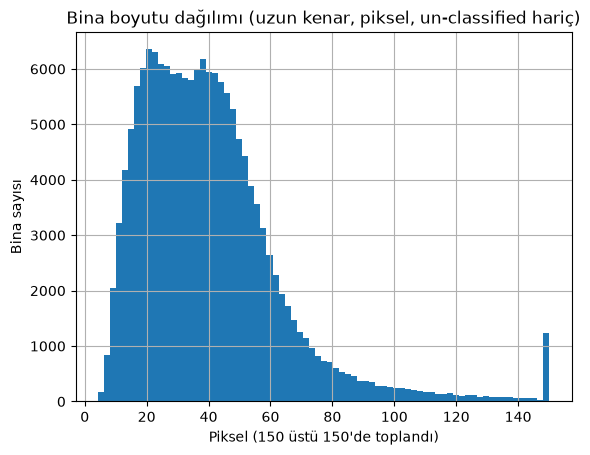

In [10]:
# Bina sınır kutuları: yalnızca post-disaster JSON'lar, features -> xy -> wkt alanı, shapely ile
rows = []
for path in sorted(LABEL_DIR.glob("*_post_disaster.json")):
    label = json.loads(path.read_text(encoding="utf-8"))
    meta = label["metadata"]
    image_id = path.stem.replace("_post_disaster", "")
    for b in label["features"]["xy"]:
        geom = shapely_wkt.loads(b["wkt"])
        x_min, y_min, x_max, y_max = geom.bounds
        rows.append({
            "image_id": image_id,
            "disaster": meta["disaster"],
            "disaster_type": meta["disaster_type"],
            "damage": b["properties"].get("subtype", "unknown"),
            "uid": b["properties"].get("uid"),
            "x_min": x_min, "y_min": y_min, "x_max": x_max, "y_max": y_max,
            "is_valid": geom.is_valid,
        })

buildings = pd.DataFrame(rows)
buildings["width"] = buildings["x_max"] - buildings["x_min"]
buildings["height"] = buildings["y_max"] - buildings["y_min"]
buildings["size"] = buildings[["width", "height"]].max(axis=1)

Path("../data/processed").mkdir(parents=True, exist_ok=True)
buildings.to_csv("../data/processed/buildings.csv", index=False)

print(f"Toplam bina: {len(buildings)}")

trainable = buildings[buildings["damage"] != "un-classified"]
print(f"un-classified hariç: {len(trainable)}\n")
print(trainable[["width", "height"]].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).round(2))

trainable["size"].clip(upper=150).hist(bins=75)
plt.title("Bina boyutu dağılımı (uzun kenar, piksel, un-classified hariç)")
plt.xlabel("Piksel (150 üstü 150'de toplandı)")
plt.ylabel("Bina sayısı")
plt.show()

150 pikselden büyük: 1,189 bina (%0.7)

Afetlere göre:
disaster
hurricane-harvey       456
mexico-earthquake      254
hurricane-michael      211
hurricane-florence      65
socal-fire              57
santa-rosa-wildfire     54
palu-tsunami            48
midwest-flooding        42
hurricane-matthew        2
dtype: int64 

Hasar sınıfına göre:
damage
no-damage        895
major-damage     174
minor-damage      94
destroyed         20
un-classified      6
Name: count, dtype: int64 

En az bir kenarı >= eşik:
 esik_px  bina_sayisi
     150         1189
     200          492
     256          245
     300          148
     400           41
     500           14
     600            7
     700            3
     800            1
     900            1
    1000            1 



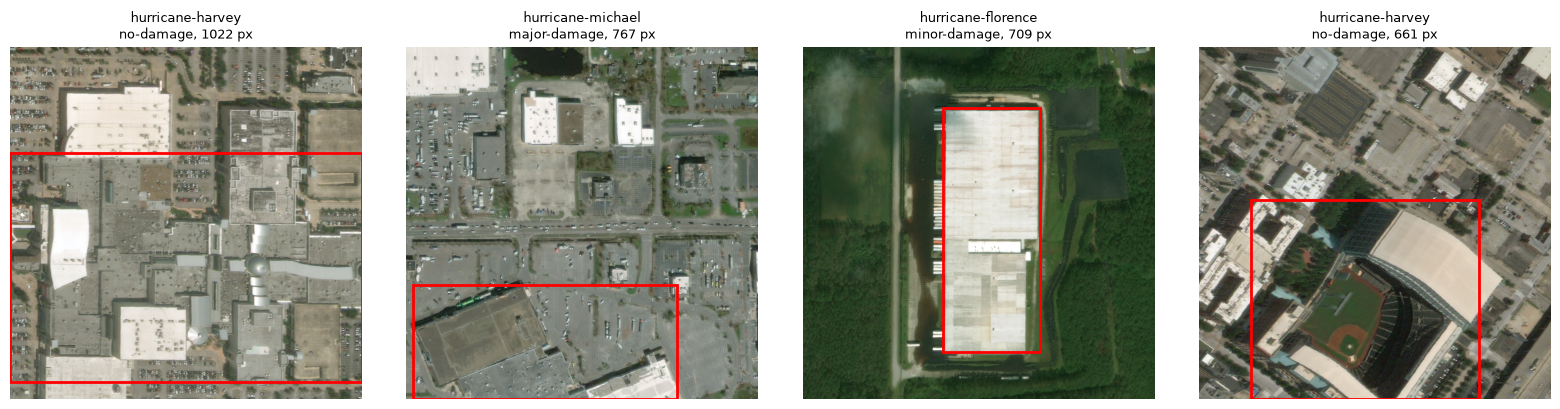

In [11]:
big = buildings[buildings["size"] > 150]
print(f"150 pikselden büyük: {len(big):,} bina (%{len(big) / len(buildings) * 100:.1f})\n")

print("Afetlere göre:")
print(big.groupby("disaster").size().sort_values(ascending=False), "\n")

print("Hasar sınıfına göre:")
print(big["damage"].value_counts(), "\n")

# Tüm poligonlar üzerinde: en az bir kenarı eşikten uzun olan bina sayısı
thresholds = [150, 200, 256, 300, 400, 500, 600, 700, 800, 900, 1000]
size_table = pd.DataFrame({
    "esik_px": thresholds,
    "bina_sayisi": [int((buildings["size"] >= t).sum()) for t in thresholds],
})
print("En az bir kenarı >= eşik:")
print(size_table.to_string(index=False), "\n")

# En büyük 4 poligonu, tüm görüntü üzerinde göster
sample = big.sort_values("size", ascending=False).drop_duplicates("image_id").head(4)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (_, r) in zip(axes, sample.iterrows()):
    img = Image.open(IMG_DIR / f"{r['image_id']}_post_disaster.png")
    ax.imshow(img)
    ax.add_patch(patches.Rectangle((r["x_min"], r["y_min"]), r["width"], r["height"],
                                   fill=False, edgecolor="red", linewidth=2))
    ax.set_title(f"{r['disaster']}\n{r['damage']}, {r['size']:.0f} px", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [12]:
import numpy as np

# Ortak bozuk poligon kuralı (Pınar ve Bahar): geçersiz geometri VEYA çok ince VEYA aşırı uzun
short_side = buildings[["width", "height"]].min(axis=1)
long_side = buildings[["width", "height"]].max(axis=1)

# Kısa kenar 0 ise oran sonsuz kabul edilir
buildings["aspect_ratio"] = np.where(short_side > 0, long_side / short_side.where(short_side > 0, 1), np.inf)

rule_invalid = ~buildings["is_valid"]
rule_thin = short_side < 3
rule_long = buildings["aspect_ratio"] > 10

buildings["is_bad_polygon"] = rule_invalid | rule_thin | rule_long
bad = buildings["is_bad_polygon"]

print(f"Geçersiz geometri : {rule_invalid.sum()}")
print(f"Kısa kenar < 3    : {rule_thin.sum()}")
print(f"Aspect ratio > 10 : {rule_long.sum()}")
print(f"Birleşim          : {bad.sum()} (%{bad.mean() * 100:.2f})\n")
print("Bozuk poligonların hasar sınıfları:")
print(buildings.loc[bad, "damage"].value_counts())

Geçersiz geometri : 1
Kısa kenar < 3    : 91
Aspect ratio > 10 : 118
Birleşim          : 177 (%0.11)

Bozuk poligonların hasar sınıfları:
damage
no-damage        117
un-classified     26
major-damage      21
destroyed          9
minor-damage       4
Name: count, dtype: int64


In [13]:
# Görüntü sınırını (0..1024) aşan poligonlar. Bu bir silme kuralı DEĞİL, yalnızca bilgi sütunu:
# bu binalar eğitimden çıkarılmaz, Faz 3'te crop koordinatları 0..1024 aralığına clamp edilir.
IMG_SIZE = 1024
buildings["out_of_bounds"] = (
    (buildings["x_min"] < 0) | (buildings["y_min"] < 0)
    | (buildings["x_max"] > IMG_SIZE) | (buildings["y_max"] > IMG_SIZE)
)
print(f"Görüntü sınırını aşan poligon: {buildings['out_of_bounds'].sum()}")

columns = ["image_id", "disaster", "disaster_type", "damage", "uid",
           "x_min", "y_min", "x_max", "y_max", "is_valid",
           "width", "height", "size", "aspect_ratio", "is_bad_polygon", "out_of_bounds"]
buildings = buildings[columns]
buildings.to_csv("../data/processed/buildings.csv", index=False)
print(f"\nbuildings.csv kaydedildi: {len(buildings)} satır, {len(columns)} sütun")

Görüntü sınırını aşan poligon: 2476



buildings.csv kaydedildi: 162787 satır, 16 sütun


In [14]:
from pathlib import Path
import pandas as pd

LABEL_DIR = Path("../data/train/labels")
buildings = pd.read_csv("../data/processed/buildings.csv")

all_pairs = pd.Series(
    [p.name.split("_")[0] for p in LABEL_DIR.glob("*_post_disaster.json")]
).value_counts().rename("toplam_cift")

with_buildings = buildings.groupby("disaster")["image_id"].nunique().rename("binali_cift")

check = pd.concat([all_pairs, with_buildings], axis=1).fillna(0).astype(int)
check["binasiz_cift"] = check["toplam_cift"] - check["binali_cift"]
print(check)
print("\nToplam:", check.sum().to_dict())

                     toplam_cift  binali_cift  binasiz_cift
socal-fire                   823          408           415
hurricane-michael            343          334             9
hurricane-florence           319          306            13
hurricane-harvey             319          300            19
midwest-flooding             279          244            35
hurricane-matthew            238          223            15
santa-rosa-wildfire          226          219             7
mexico-earthquake            121          121             0
palu-tsunami                 113          111             2
guatemala-volcano             18           17             1

Toplam: {'toplam_cift': 2799, 'binali_cift': 2283, 'binasiz_cift': 516}


## WKT Parsing Validation

- Eski `wkt_to_xy` fonksiyonu koordinatları `-?\d+(?:\.\d+)?` regex'i ile okuyordu; bu regex bilimsel gösterimi tanımıyor.
- Bazı WKT koordinatlarında `e-06` gibi bilimsel gösterim var (ör. `-8.312904688665519e-06`). Regex bu sayıyı `-8.31...` ve `-06` olarak ikiye bölüyor.
- Araya fazladan bir sayı girdiği için sonraki x/y çiftleri kayıyor ve sınır kutusu (bounding box) yanlış hesaplanıyor.
- Sınır kutusu hesapları Shapely'ye (`geom.bounds`) geçirildi.
- Yeni sonuçlar Pınar'ın bağımsız Shapely analizi ile doğrulandı.

Aşağıdaki hücre eski regex ile Shapely sonuçlarını tüm post-disaster poligonlarda karşılaştırır.

In [15]:
import re
import json
from pathlib import Path
from shapely import wkt as shapely_wkt

LABEL_DIR = Path("../data/train/labels")

def wkt_to_xy_eski(w):
    nums = [float(v) for v in re.findall(r"-?\d+(?:\.\d+)?", w)]
    return list(zip(nums[0::2], nums[1::2]))

bilimsel_desen = re.compile(r"\d[eE][-+]?\d")
toplam = bilimsel = farkli = 0
ornek = None

for path in sorted(LABEL_DIR.glob("*_post_disaster.json")):
    label = json.loads(path.read_text(encoding="utf-8"))
    for bina in label["features"]["xy"]:
        w = bina["wkt"]
        toplam += 1
        if bilimsel_desen.search(w):
            bilimsel += 1
        xy = wkt_to_xy_eski(w)
        if not xy:
            continue
        xs, ys = zip(*xy)
        eski = (min(xs), min(ys), max(xs), max(ys))
        dogru = shapely_wkt.loads(w).bounds
        if max(abs(a - b) for a, b in zip(eski, dogru)) > 0.5:
            farkli += 1
            if ornek is None:
                ornek = (path.name, w[:150], eski, dogru)

print(f"Toplam poligon                  : {toplam:,}")
print(f"Bilimsel gösterim içeren         : {bilimsel:,}")
print(f"Eski yöntemle sınır kutusu yanlış: {farkli:,}")
print("\nİlk yanlış örnek:", ornek)

Toplam poligon                  : 162,787
Bilimsel gösterim içeren         : 2,825
Eski yöntemle sınır kutusu yanlış: 2,825

İlk yanlış örnek: ('hurricane-florence_00000018_post_disaster.json', 'POLYGON ((-8.312904688665519e-06 697.2773224093805, 9.122209070071284 675.9290296886467, 20.25680880223996 680.7010010024893, 4.099081370694565 718.70', (-8.312904688665519, -8.312777334670226, 718.7093339268637, 716.7000828466539), (-8.312904688665519e-06, 675.9290296886467, 20.25680880223996, 718.7093339268637))


## Faz 2 Sonuç

**Veri**
- xBD / xView2 Challenge Training Set kullanıldı (test, hold ve Tier3 dahil değil).
- 2799 pre/post görüntü çifti eksiksiz eşleşti.
- Toplam 162787 bina analiz edildi; 159794 bina dört kullanılabilir hasar sınıfında (no-damage, minor-damage, major-damage, destroyed).
- `un-classified` (2993 bina) eğitimden çıkarılacak.

**Dağılım**
- Ciddi sınıf dengesizliği var: binaların büyük çoğunluğu no-damage.
- Afet bazlı dağılımlar çıkarıldı (`results/faz2_afet_hasar_dagilimi.csv`).
- Hurricane Matthew pipeline doğrulama olayı olarak kullanılacak: 238 toplam görüntü çifti; bunların 223'ünde en az bir bina anotasyonu bulunmaktadır.

**Geometri**
- Regex tabanlı WKT parser hatalı bulundu (bilimsel gösterimi okuyamıyor); sınır kutusu hesabı Shapely'ye geçirildi.
- Ortak bozuk poligon kuralı: `invalid geometry OR short_side < 3 OR aspect_ratio > 10` → 177 bozuk poligon.
- 2476 poligon görüntü sınırını aşıyor (out-of-bounds); bunlar atılmayacak, Faz 3'te crop koordinatları 0..1024 aralığına clamp edilecek.

**Sonraki adım**
- CNN / ResNet için 128x128 başlangıç patch boyutu değerlendirilecek.
- Faz 3'e geçilebilir.